# EV Charging Usage Pattern Analysis — Exploratory Data Analysis (EDA)

## Objective
The purpose of EDA is to understand **how the EV charging data behaves before machine-learning modeling**.

1. **Univariate analysis** — one variable at a time  
2. **Bivariate analysis** — relationship between two variables  
3. **Multivariate analysis** — relationship among three or more variables  
4. **Correlation analysis** — strength and direction of association between numeric variables

## 1. Load the cleaned dataset and create time-based EDA features

The cleaned charging dataset is loaded and the main timestamp column, `start_full`, is converted to datetime format.

The initial EDA preparation creates start_hour, start_date, day_of_week_number, and day_of_week from start_full. Readable labels are also created for charger company and charger type. Additional calendar, time-of-day, and historical-usage features are created later in the Feature Engineering section.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import os

# 1. Read the cleaned dataset
# Load cleaned dataset
df = pd.read_csv('data/ChargingRecords_cleaned.csv')

print("Rows used for EDA:",len(df))
print("Columns used for EDA:",len(df.columns))

Rows used for EDA: 72241
Columns used for EDA: 20


In [2]:
# 2. Prepare date and time columns
# start_full was created by the cleaning script.
df["start_full"] = pd.to_datetime(df["start_full"], errors="coerce")
df["end_full"] = pd.to_datetime(df["end_full"], errors="coerce")

# These columns make time analysis easier.
df["start_hour"] = df["start_full"].dt.hour
df["start_date"] = df["start_full"].dt.date
df["day_of_week_number"] = df["start_full"].dt.dayofweek

df["start_date"] = (df["start_full"].dt.normalize())

day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday",
}

df["day_of_week"] = df["day_of_week_number"].map(day_names)

# These labels make charts easier to understand.
df["chargercompany_label"] = df["chargercompany"].map(
    {0: "Company 0", 1: "Company 1"}
)
df["chargertype_label"] = df["chargertype"].map(
    {0: "Type 0", 1: "Type 1"}
)

In [3]:
# 3. Basic EDA checks
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique locations:")
print(df["location"].unique())


Data types:
userid                           int64
chargerid                        int64
chargercompany                   int64
location                        object
chargertype                      int64
startday                        object
starttime                       object
endday                          object
endtime                         object
startdatetime                   object
enddatetime                     object
duration                       float64
demand                         float64
start_full              datetime64[ns]
end_full                datetime64[ns]
duration_original                int64
duration_calculated            float64
duration_mismatch                 bool
duration_outlier                  bool
demand_outlier                    bool
start_hour                       int32
start_date              datetime64[ns]
day_of_week_number               int32
day_of_week                     object
chargercompany_label            object
chargertype_

## 2. Quick structural validation of the EDA dataset

- first few rows of time based created column
- column names

In [4]:
df[['start_full','start_hour','start_date','day_of_week_number','day_of_week','chargercompany_label','chargertype_label']].head()

,start_full,start_hour,start_date,day_of_week_number,day_of_week,chargercompany_label,chargertype_label
0,2021-09-30 17:14:26,17,2021-09-30,3,Thursday,Company 1,Type 0
1,2021-09-30 18:22:36,18,2021-09-30,3,Thursday,Company 1,Type 0
2,2021-09-30 18:57:46,18,2021-09-30,3,Thursday,Company 1,Type 0
3,2021-09-30 19:52:22,19,2021-09-30,3,Thursday,Company 1,Type 0
4,2021-09-30 20:48:46,20,2021-09-30,3,Thursday,Company 1,Type 0


In [5]:
df.columns

Index(['userid', 'chargerid', 'chargercompany', 'location', 'chargertype',
       'startday', 'starttime', 'endday', 'endtime', 'startdatetime',
       'enddatetime', 'duration', 'demand', 'start_full', 'end_full',
       'duration_original', 'duration_calculated', 'duration_mismatch',
       'duration_outlier', 'demand_outlier', 'start_hour', 'start_date',
       'day_of_week_number', 'day_of_week', 'chargercompany_label',
       'chargertype_label'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72241 entries, 0 to 72240
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   userid                72241 non-null  int64         
 1   chargerid             72241 non-null  int64         
 2   chargercompany        72241 non-null  int64         
 3   location              72241 non-null  object        
 4   chargertype           72241 non-null  int64         
 5   startday              72241 non-null  object        
 6   starttime             72241 non-null  object        
 7   endday                72241 non-null  object        
 8   endtime               72241 non-null  object        
 9   startdatetime         72241 non-null  object        
 10  enddatetime           72241 non-null  object        
 11  duration              72241 non-null  float64       
 12  demand                72241 non-null  float64       
 13  start_full      

# 3. Univariate analysis — numerical variables

The two main numerical variables studied here are:

- `duration` — length of a charging session
- `demand` — charging demand

### Statistical interpretation

#### Duration
```text
mean   = 156.71 minutes
median = 115 minutes
Q1     = 41 minutes
Q3     = 205 minutes
max    = 4717 minutes
```

The mean is higher than the median and the maximum is very large. This suggests that a smaller number of long charging sessions are pulling the average upward.

#### Demand
```text
mean   = 17.57
median = 14.25
Q1     = 7.69
Q3     = 23.20
max    = 97.00
```

Again, the mean is greater than the median, suggesting more observations are concentrated at lower/moderate demand with a tail toward higher values.

## Skewness

```text
Duration skewness = 3.34
Demand skewness   = 1.20
```

Interpretation:
- `duration` is **strongly right-skewed**
- `demand` is also **right-skewed**, but less severely

---

## Kurtosis

```text
Duration kurtosis = 37.45
Demand kurtosis   = 1.18
```

The very high duration kurtosis indicates a distribution with substantial tail/extreme-value behaviour.

---

Most charging sessions are concentrated at shorter to moderate durations, while a smaller number of sessions extend to very long durations. Charging demand is similarly concentrated at lower to moderate values with fewer high-demand sessions. These long right tails explain why the mean is greater than the median for both variables.

# Log transformation

```text
Original duration skew =  3.34
Log duration skew      = -0.75

Original demand skew   =  1.20
Log demand skew        = -0.71
```

Log transformation substantially reduces the original right skew, but it does not make either distribution perfectly normal. The transformed variables become mildly left-skewed and show visible concentration at several values.

--- ORIGINAL DATA SUMMARY ---
           duration        demand
count  72241.000000  72241.000000
mean     156.705472     17.571427
std      159.136511     13.459140
min        1.000000      0.010000
25%       41.000000      7.690000
50%      115.000000     14.250000
75%      205.000000     23.200000
max     4717.000000     97.000000
Variance of duration: 25324.429185035067 |Variance of demand: 181.14843673313882
Skew of duration: 3.3387821101251633 | Skew of demand: 1.195048956517249
Kurtosis of duration: 37.444779261479916 | Kurtosis of demand: 1.18453389883893


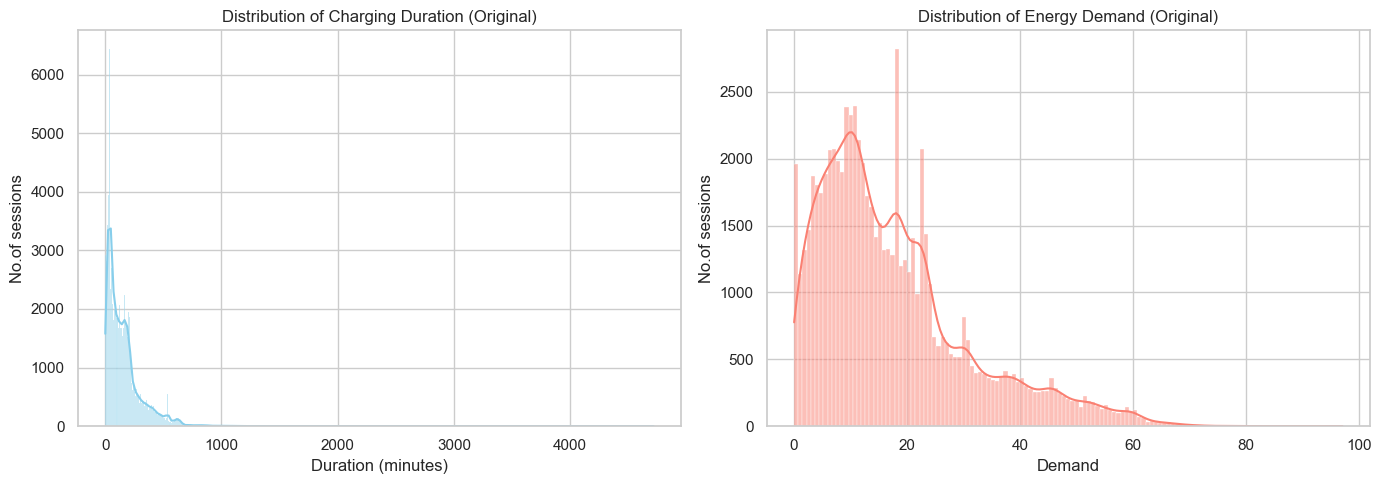


--- LOG-TRANSFORMED DATA SUMMARY ---
       log_duration    log_demand
count  72241.000000  72241.000000
mean       4.557575      2.627377
std        1.130419      0.840751
min        0.693147      0.009950
25%        3.737670      2.162173
50%        4.753590      2.724580
75%        5.327876      3.186353
max        8.459140      4.584967
Variance of log_duration: 1.2778480228279985 |Variance of log_demand: 0.7068616757849345
Skew of log_duration: -0.7482599996798944 | Skew of log_demand: -0.7055696228277972
Kurtosis of log_duration: 0.7664190143564888 | Kurtosis of log_demand: 0.46534779652916036


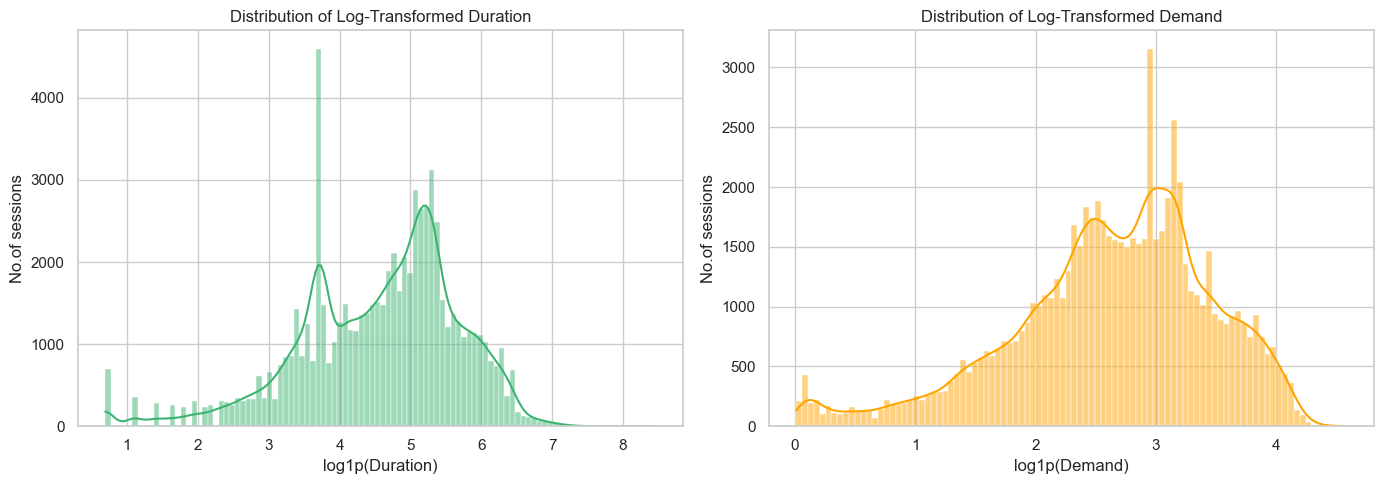

In [7]:
sns.set_theme(style="whitegrid")

# 1. Original data stats summary

numeric_columns = ["duration", "demand"]

print("--- ORIGINAL DATA SUMMARY ---")
print(df[numeric_columns].describe())
print("Variance of duration:", df['duration'].var(),"|Variance of demand:", df['demand'].var())
print("Skew of duration:", df['duration'].skew(),"| Skew of demand:", df['demand'].skew())
print("Kurtosis of duration:", df['duration'].kurt(), "| Kurtosis of demand:", df['demand'].kurt())

# Original Side-by-Side Histograms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['duration'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Charging Duration (Original)')
axes[0].set_xlabel('Duration (minutes)')
axes[0].set_ylabel('No.of sessions')

sns.histplot(df['demand'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Energy Demand (Original)')
axes[1].set_xlabel('Demand')
axes[1].set_ylabel('No.of sessions')

plt.tight_layout()
plt.savefig("images/eda_demand_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. LOG-TRANSFORMED DATA: STATS & PLOTS
df['log_duration'] = np.log1p(df['duration'])
df['log_demand'] = np.log1p(df['demand'])

log_columns = ["log_duration", "log_demand"]

print("\n--- LOG-TRANSFORMED DATA SUMMARY ---")
print(df[log_columns].describe())
print("Variance of log_duration:", df['log_duration'].var(),"|Variance of log_demand:", df['log_demand'].var())
print("Skew of log_duration:", df['log_duration'].skew(), "| Skew of log_demand:", df['log_demand'].skew())
print("Kurtosis of log_duration:", df['log_duration'].kurt(), "| Kurtosis of log_demand:", df['log_demand'].kurt())

# Log-Transformed Side-by-Side Histograms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['log_duration'], kde=True, ax=axes[0], color='mediumseagreen')
axes[0].set_title('Distribution of Log-Transformed Duration')
axes[0].set_xlabel('log1p(Duration)')
axes[0].set_ylabel('No.of sessions')

sns.histplot(df['log_demand'], kde=True, ax=axes[1], color='orange')
axes[1].set_title('Distribution of Log-Transformed Demand')
axes[1].set_xlabel('log1p(Demand)')
axes[1].set_ylabel('No.of sessions')

plt.tight_layout()
plt.show()

# 3.1 Univariate analysis — categorical variables

- `location`
- `chargercompany_label`
- `chargertype_label`

For each category it calculates:

1. **Value count** — number of charging sessions
2. **Percentage** — share of total charging sessions
3. **Count plot** — visual comparison

### location output
```text
apartment          13,970 sessions  ≈ 19.34%
public area        13,949 sessions  ≈ 19.31%
resort              8,755 sessions  ≈ 12.12%
hotel               8,495 sessions  ≈ 11.76%
...
bus garage              29 sessions
```

### Interpretation
- Apartment and public-area locations account for the largest number of recorded charging sessions.
- Bus-garage and accommodation categories have very few observations compared with the major locations.

### Charger company sample
```text
Company 1 ≈ 62.83%
Company 0 ≈ 37.17%
```


Value counts for: location
location
apartment             13970
public area           13949
resort                 8755
hotel                  8495
company                7530
public institution     6962
public parking lot     3363
market                 2958
restaurant             2214
camping                1621
sightseeing            1185
golf                   1026
accommodation           184
bus garage               29
Name: count, dtype: int64

Percentage for : location
location
apartment             19.338049
public area           19.308980
resort                12.119157
hotel                 11.759250
company               10.423444
public institution     9.637187
public parking lot     4.655251
market                 4.094628
restaurant             3.064742
camping                2.243878
sightseeing            1.640343
golf                   1.420246
accommodation          0.254703
bus garage             0.040143
Name: proportion, dtype: float64


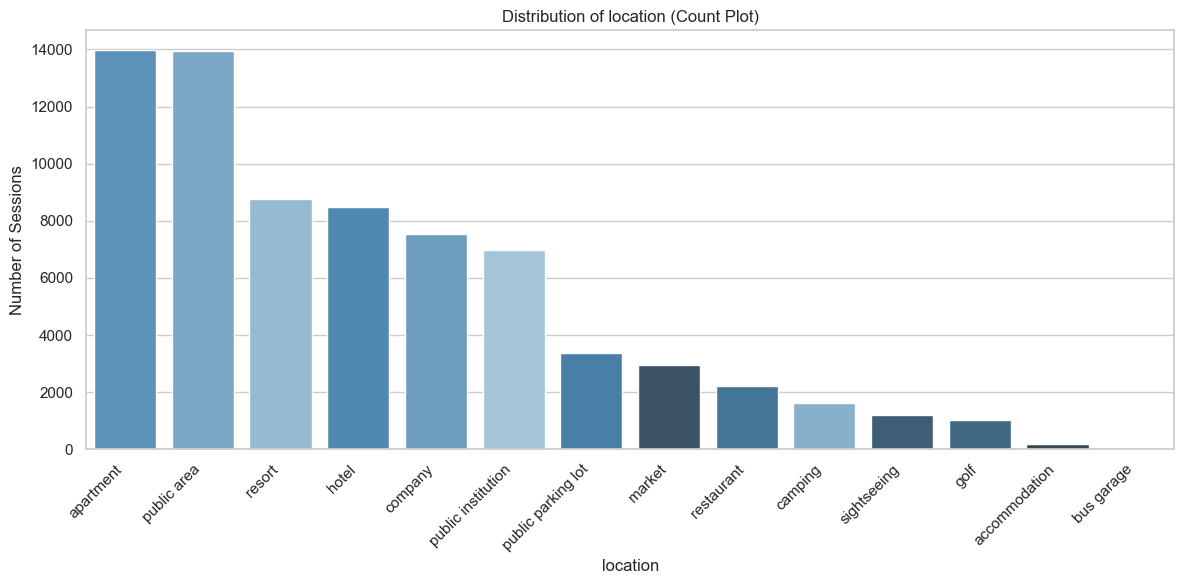


Value counts for: chargercompany_label
chargercompany_label
Company 1    45391
Company 0    26850
Name: count, dtype: int64

Percentage for : chargercompany_label
chargercompany_label
Company 1    62.83274
Company 0    37.16726
Name: proportion, dtype: float64


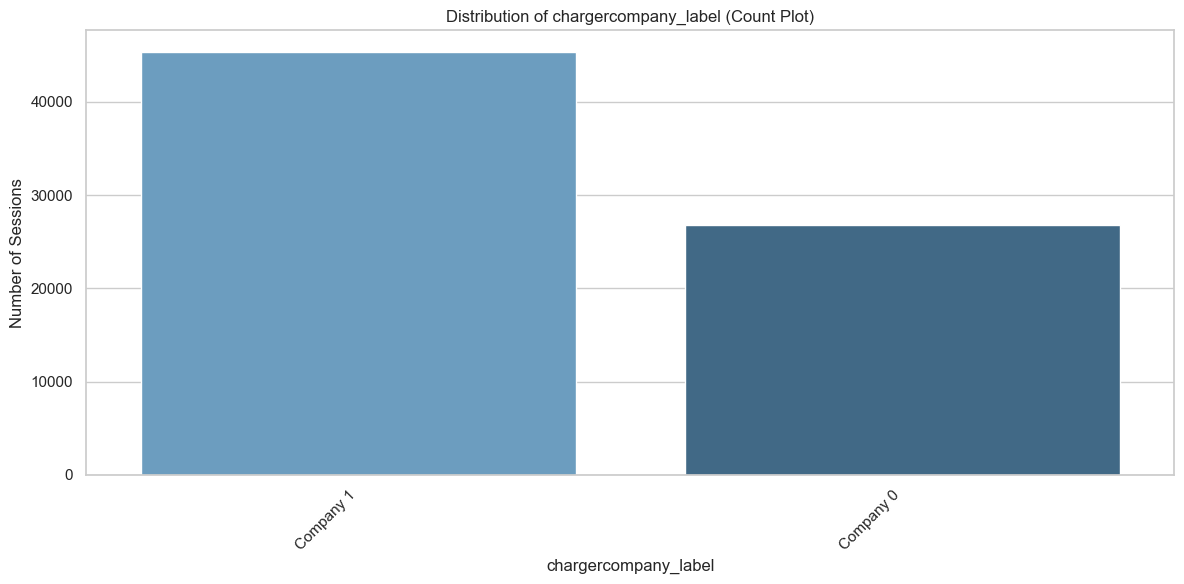


Value counts for: chargertype_label
chargertype_label
Type 0    57535
Type 1    14706
Name: count, dtype: int64

Percentage for : chargertype_label
chargertype_label
Type 0    79.643139
Type 1    20.356861
Name: proportion, dtype: float64


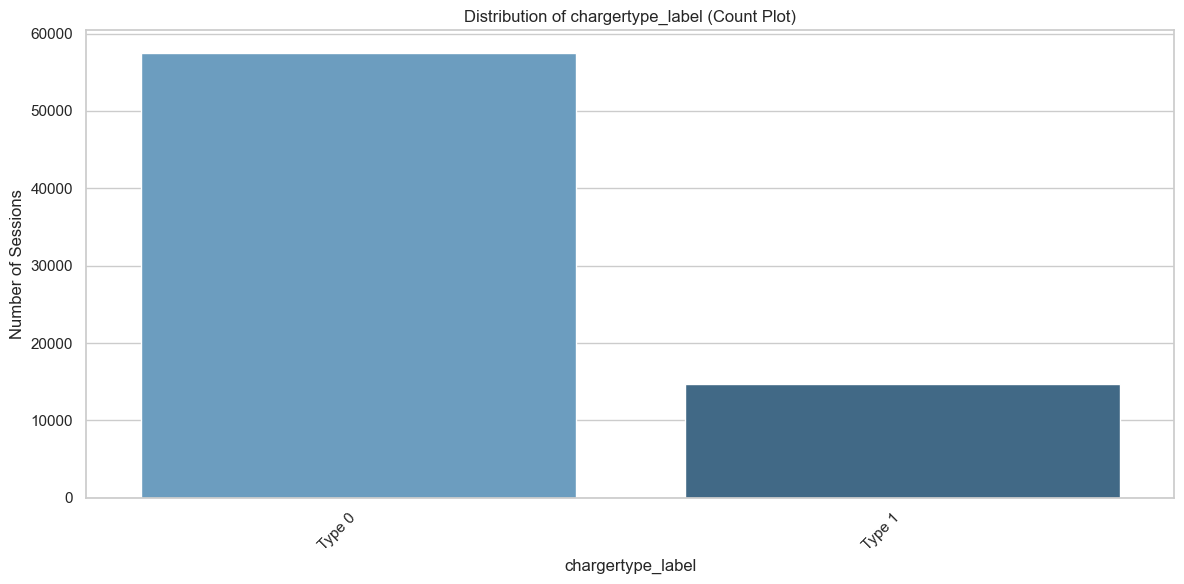

In [8]:
# Seaborn style set
sns.set_theme(style="whitegrid")

# categorical columns
categorical_columns = ["location","chargercompany_label", "chargertype_label"]

for col in categorical_columns:
    print(f"\n==========================================")
    print(f"Value counts for: {col}")
    print(f"==========================================")
    print(df[col].value_counts())
    
    print(f"\nPercentage for : {col}")
    print(df[col].value_counts(normalize=True) * 100)
    
    # Seaborn Countplot
    plt.figure(figsize=(12, 6))
    
    sns.countplot(
        data=df, 
        x=col, 
        hue = col,
        order=df[col].value_counts().index, 
        palette='Blues_d',
        color="steelblue"
    )
    
    plt.ylabel("Number of Sessions")
    plt.title(f"Distribution of {col} (Count Plot)")
    plt.xlabel(col)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# 3.2 Time-based usage-pattern analysis

Charging sessions by start hour and day_of_week

### hourly output
```text
18:00 → 6,448 sessions
17:00 → 6,307 sessions
19:00 → 5,461 sessions
16:00 → 5,107 sessions
...
03:00 →   134 sessions
```

### Interpretation
The charging dataset shows much heavier session activity in the late afternoon/evening, especially around **17:00–19:00**, while very early morning hours have much lower usage.

The next chart adds `day_name` as a hue, allowing us to compare **hour + day of week together**.

That moves from a single-variable count toward a multi-dimensional usage-pattern view.

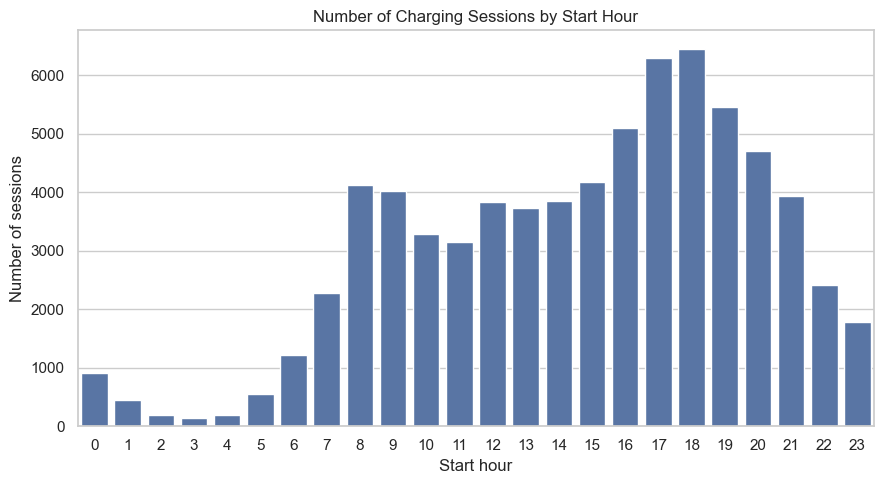

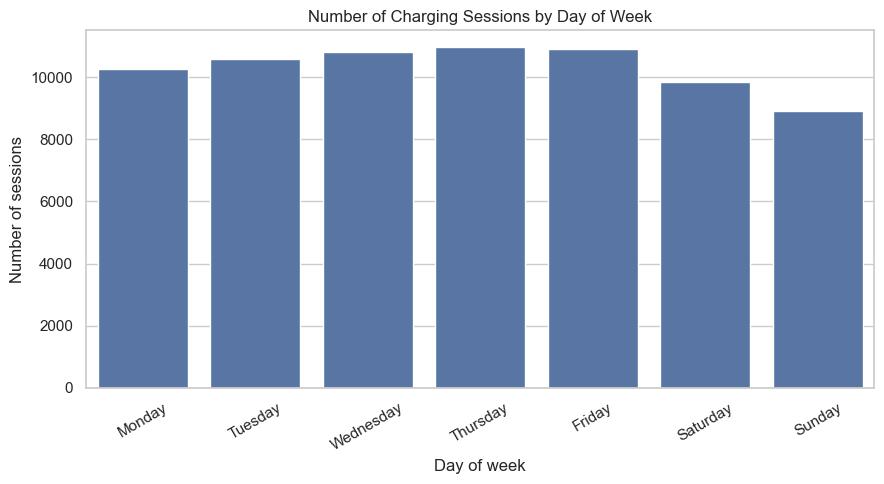

In [9]:
# 6. Univariate analysis of time variables
# These charts show when charging sessions happen.
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="start_hour", order=range(24))
plt.title("Number of Charging Sessions by Start Hour")
plt.xlabel("Start hour")
plt.ylabel("Number of sessions")
plt.tight_layout()
plt.savefig("images/eda_sessions_by_hour.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

ordered_days = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="day_of_week", order=ordered_days)
plt.title("Number of Charging Sessions by Day of Week")
plt.xlabel("Day of week")
plt.ylabel("Number of sessions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
plt.close()

# 4. Bivariate Analysis
## 4.1 Duration vs Demand

A scatter plot places:
- `duration` on the X-axis
- `demand` on the Y-axis

Each point represents one charging session.

### Scatter plot
Scatter plots are useful for two numeric variables because they show:
- direction of relationship
- spread
- clusters
- unusual observations
- whether a straight-line relationship is reasonable

A regression trend line is added to the original-scale plot.

The notebook also plots the relationship using log-transformed variables. This compresses extreme values so the dense central pattern becomes easier to inspect.

### Interpretation:

Longer sessions generally have higher charging demand, but duration alone does not fully explain demand. The wide spread and distinct bands suggest that other factors, such as charger type, charging rate, location, or company, may change the relationship between duration and demand.

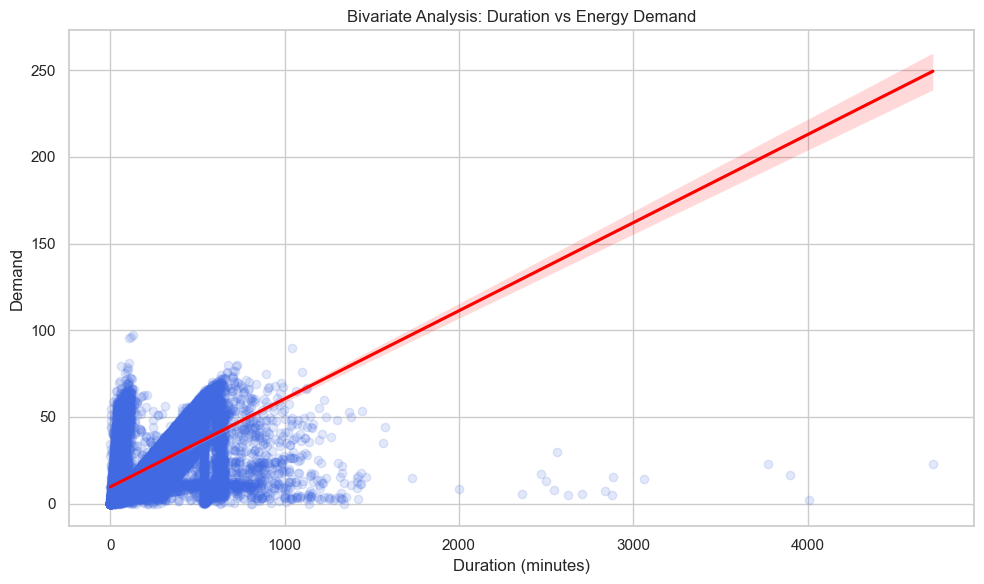

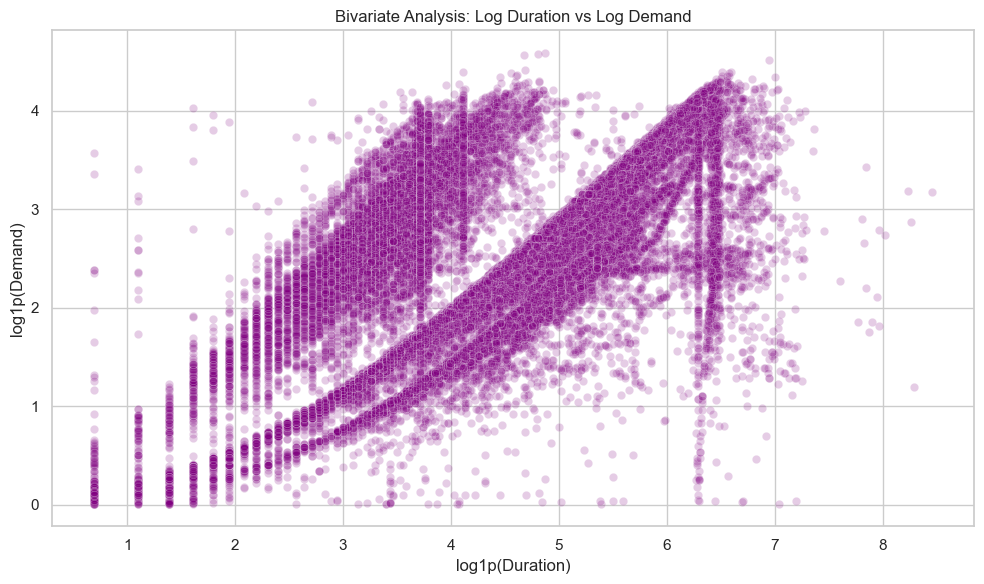

In [10]:
sns.set_theme(style="whitegrid")

# Method 1: Scatter Plot with Trend Line (Regplot)
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df, 
    x='duration', 
    y='demand', 
    scatter_kws={'alpha': 0.15, 'color': 'royalblue'}, # alpha transparent
    line_kws={'color': 'red'}                          # red trend line
)

plt.title('Bivariate Analysis: Duration vs Energy Demand')
plt.xlabel('Duration (minutes)')
plt.ylabel('Demand')
plt.tight_layout()
plt.savefig("images/eda_duration_vs_demand.png", dpi=300, bbox_inches="tight")
plt.show()

# Method 2: Log-transformed plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='log_duration', 
    y='log_demand', 
    alpha=0.2, 
    color='purple'
)

plt.title('Bivariate Analysis: Log Duration vs Log Demand')
plt.xlabel('log1p(Duration)')
plt.ylabel('log1p(Demand)')
plt.tight_layout()
plt.show()

## 4.2 Pearson vs Spearman correlation for Duration and Demand

### Pearson correlation

```text
Original Pearson correlation ≈ 0.601
Log-scale Pearson correlation ≈ 0.698
```

Interpretation:
- Both are positive.
- Duration and demand have a **moderate positive association**.
- On the log scale, the linear relationship becomes somewhat stronger.

### Spearman correlation

```text
Original Spearman correlation ≈ 0.633
Log Spearman correlation      ≈ 0.633
```

In [11]:
# 1. Pearson Correlation (Linear Relationship)
pearson_orig = df[['duration', 'demand']].corr(method='pearson')
pearson_log = df[['log_duration', 'log_demand']].corr(method='pearson')

# 2. Spearman Correlation (Monotonic / Rank-based Relationship)
spearman_orig = df[['duration', 'demand']].corr(method='spearman')
spearman_log = df[['log_duration', 'log_demand']].corr(method='spearman') 

print("=== Pearson correlation (Original) ===")
print(pearson_orig)

print("\n=== Pearson correlation (Log-Transformed) ===")
print(pearson_log)

print("\n=== Spearman correlation (Original) ===")
print(spearman_orig)

print("\n=== Spearman correlation (Log-Transformed) ===")
print(spearman_log)

=== Pearson correlation (Original) ===
          duration    demand
duration  1.000000  0.600884
demand    0.600884  1.000000

=== Pearson correlation (Log-Transformed) ===
              log_duration  log_demand
log_duration       1.00000     0.69779
log_demand         0.69779     1.00000

=== Spearman correlation (Original) ===
          duration    demand
duration  1.000000  0.633322
demand    0.633322  1.000000

=== Spearman correlation (Log-Transformed) ===
              log_duration  log_demand
log_duration      1.000000    0.633322
log_demand        0.633322    1.000000


## 4.3 Location vs Demand

Boxplots compare the distribution of demand or duration across locations.

Demand contains skewness and extreme values. Median is less affected by unusually high sessions and therefore represents a more robust 'typical' demand across locations.

The locations are ordered by median demand. Some low-frequency locations appear to have higher typical demand, but these categories contain relatively few sessions. Their median values may therefore be less stable than the medians of locations with many sessions. These results describe the available dataset but should not be treated as strong evidence that low-frequency locations always generate higher demand.

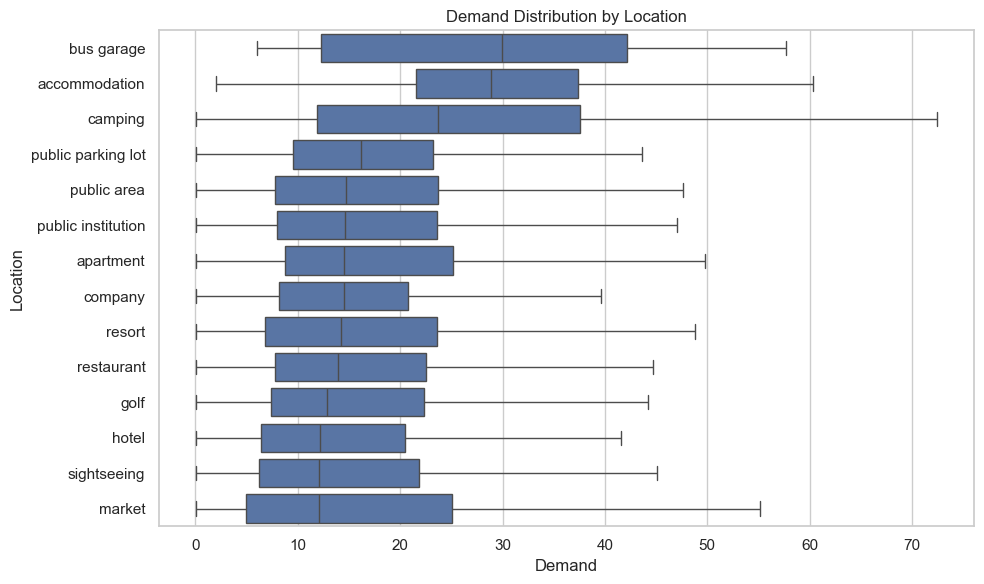

In [12]:
# 8. Category versus numeric variable: location and demand
location_order = (
    df.groupby("location")["demand"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="demand",
    y="location",
    order=location_order,
    showfliers=False,
)
plt.title("Demand Distribution by Location")
plt.xlabel("Demand")
plt.ylabel("Location")
plt.tight_layout()
plt.show()
plt.close()

## 4.4 Charger Type and Charger Company vs Duration/Demand

These boxplots compare:

- Charger Type → Duration
- Charger Type → Demand
- Charger Company → Duration
- Charger Company → Demand

For example:
- one charger type may tend to have shorter sessions
- one charger company may serve sessions with different typical demand

### interpretation
Charger company has only a small difference in typical demand, but the duration distributions differ substantially. This suggests that company-related charging behavior is expressed more through session length than demand alone.

Type 1 sessions typically have higher demand and much shorter duration than Type 0 sessions. This may indicate that the charger types serve different charging patterns. The chart demonstrates why charger type is relevant for later prediction models.

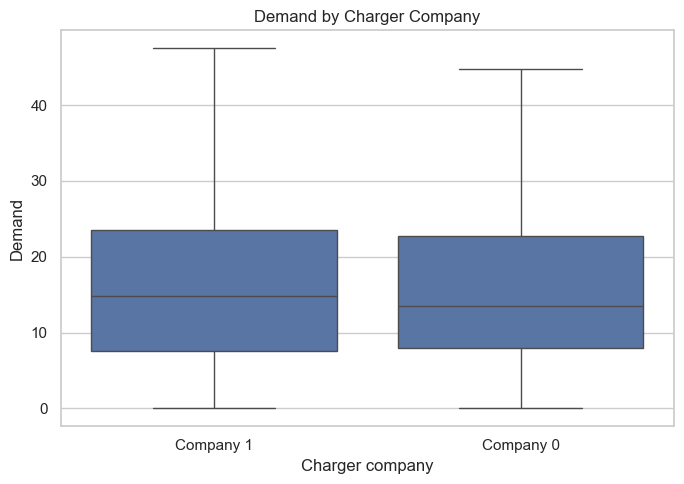

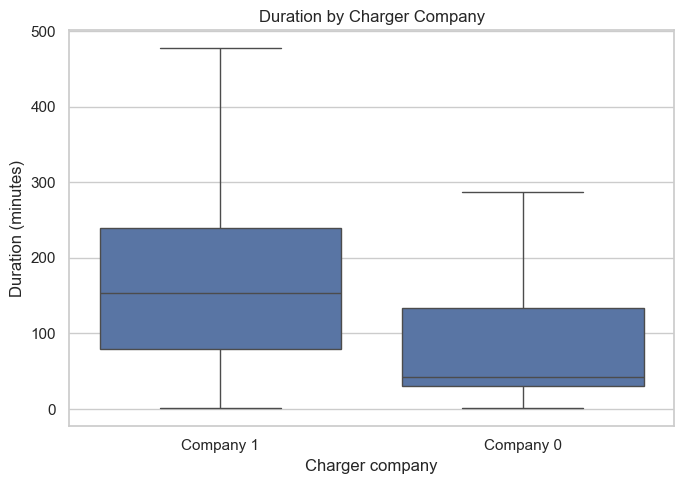

In [13]:
# 9. Company versus demand and duration
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df,
    x="chargercompany_label",
    y="demand",
    showfliers=False,
)
plt.title("Demand by Charger Company")
plt.xlabel("Charger company")
plt.ylabel("Demand")
plt.tight_layout()
plt.show()
plt.close()

plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df,
    x="chargercompany_label",
    y="duration",
    showfliers=False,
)
plt.title("Duration by Charger Company")
plt.xlabel("Charger company")
plt.ylabel("Duration (minutes)")
plt.tight_layout()
plt.show()
plt.close()

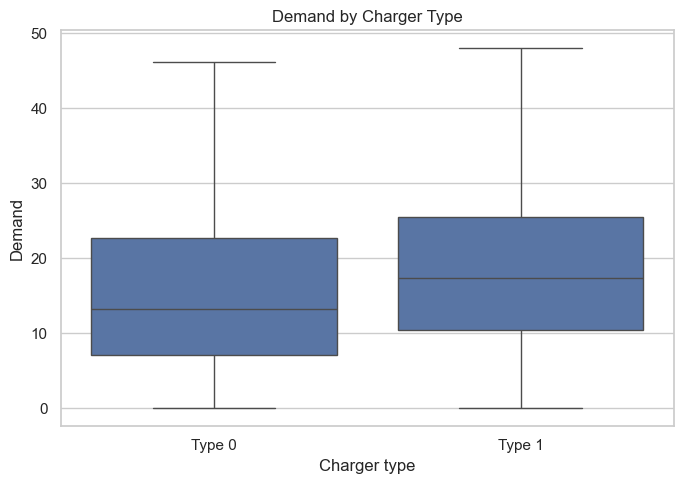

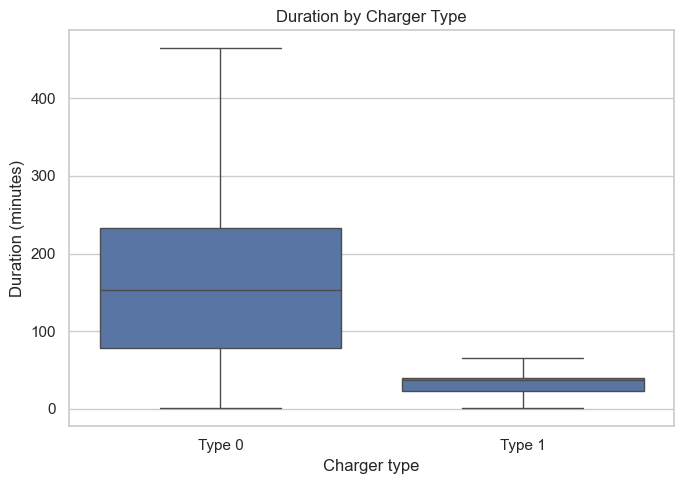

In [14]:
# 11. Charger type versus demand and duration
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df,
    x="chargertype_label",
    y="demand",
    showfliers=False,
)
plt.title("Demand by Charger Type")
plt.xlabel("Charger type")
plt.ylabel("Demand")
plt.tight_layout()
plt.savefig("images/eda_demand_by_charger_type.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df,
    x="chargertype_label",
    y="duration",
    showfliers=False,
)
plt.title("Duration by Charger Type")
plt.xlabel("Charger type")
plt.ylabel("Duration (minutes)")
plt.tight_layout()
plt.show()
plt.close()

# 4.5 Time-based demand analysis

## Mean/Median demand by charging start hour

The dataset is grouped by `start_hour`, and the **median demand** is calculated for each hour.

Demand contains skewness and extreme values. Median is less affected by unusually high sessions and therefore represents a more robust 'typical' demand for each hour.

### Interpretation
Typical demand is lowest during late morning and early afternoon and increases during the evening and night. The consistent gap between mean and median confirms that high-demand sessions pull the hourly mean upward.

Evening: more sessions
Late night: higher typical demand per session

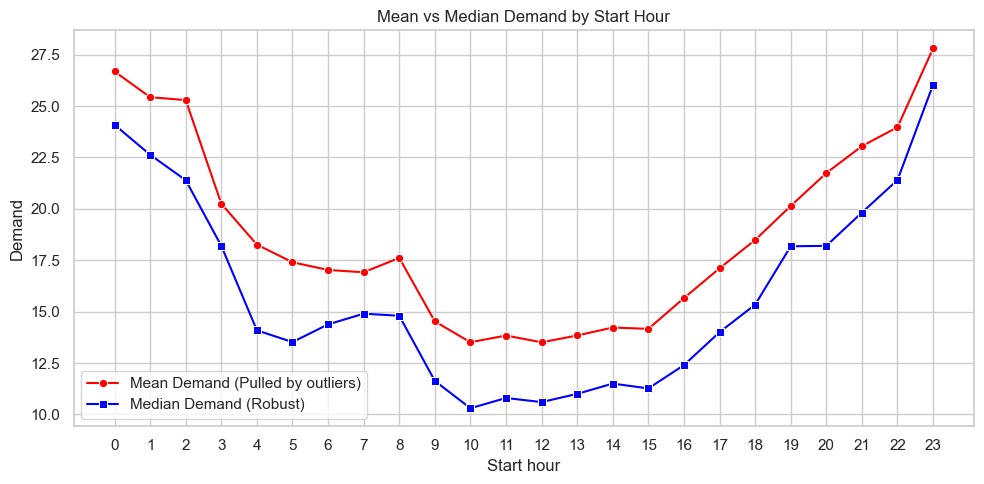

In [15]:
# 12. Time versus demand (Handling Skewness with Mean & Median)
time_agg = df.groupby("start_hour", as_index=False).agg(
    mean_demand=("demand", "mean"),
    median_demand=("demand", "median")
)

plt.figure(figsize=(10, 5))
# Plotting Mean (Affected by outliers)
sns.lineplot(
    data=time_agg, 
    x="start_hour", 
    y="mean_demand", 
    label="Mean Demand (Pulled by outliers)", 
    marker="o", 
    color="red"
)
# Plotting Median (True typical behavior)
sns.lineplot(
    data=time_agg, 
    x="start_hour", 
    y="median_demand", 
    label="Median Demand (Robust)", 
    marker="s", 
    color="blue"
)

plt.title("Mean vs Median Demand by Start Hour")
plt.xlabel("Start hour")
plt.ylabel("Demand")
plt.xticks(range(24))
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

# 5. Multivariate analysis — Location × Hour × Demand

This heatmap combines three variables:

1. `location`
2. `start_hour`
3. median `demand`

Darker cells represent higher median demand according to the selected colour scale.

### Interpretation

The heatmap shows how median charging demand varies across locations and charging start hours. Several locations show higher median demand during evening or late-night hours than during some daytime hours, although the pattern is not identical across all locations.

Darker red cells indicate higher median demand per session, while lighter yellow cells indicate lower median demand. Blank cells represent location-hour combinations without recorded sessions.

Locations with relatively few sessions, particularly bus garage and accommodation, should be interpreted cautiously because their hourly medians may not represent stable charging patterns.

This heatmap helps identify when typical demand is higher at different locations. It does not show the number of sessions or the total demand for an hour.

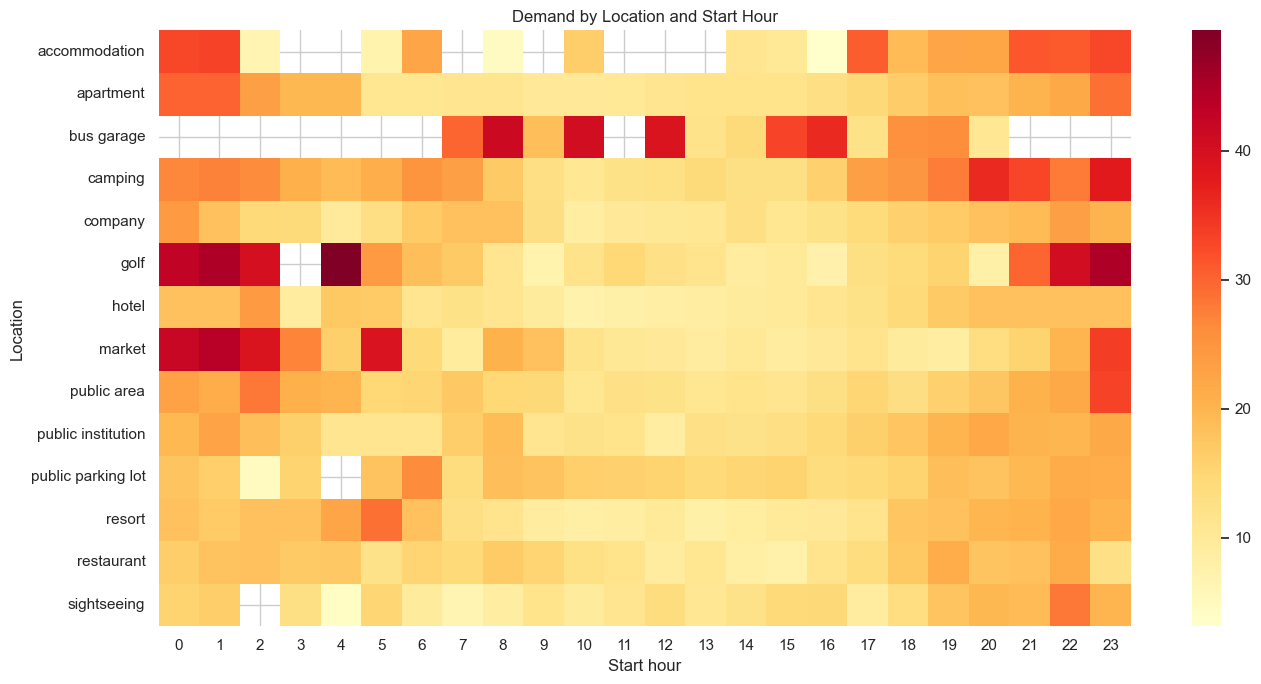

In [16]:
# =========================================================
# Multivariate Analysis
# 13. Location, hour, and median demand
# Rows are locations, columns are start hours, and cell color is demand.

demand_by_location_and_hour = df.pivot_table(
    index="location",
    columns="start_hour",
    values="demand",
    aggfunc="median",
)

plt.figure(figsize=(14, 7))
sns.heatmap(
    demand_by_location_and_hour,
    cmap="YlOrRd",
    annot=False,
)

plt.title("Demand by Location and Start Hour")
plt.xlabel("Start hour")
plt.ylabel("Location")
plt.tight_layout()
plt.savefig("images/eda_location_hour_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

## 5.1 Location × Charger Company × Demand

The data is grouped by:
- `location`
- `chargercompany_label`

For each combination, the notebook calculates:
- median demand
- median duration
- number of sessions

The bar chart compares demand across locations for the two charger-company categories.

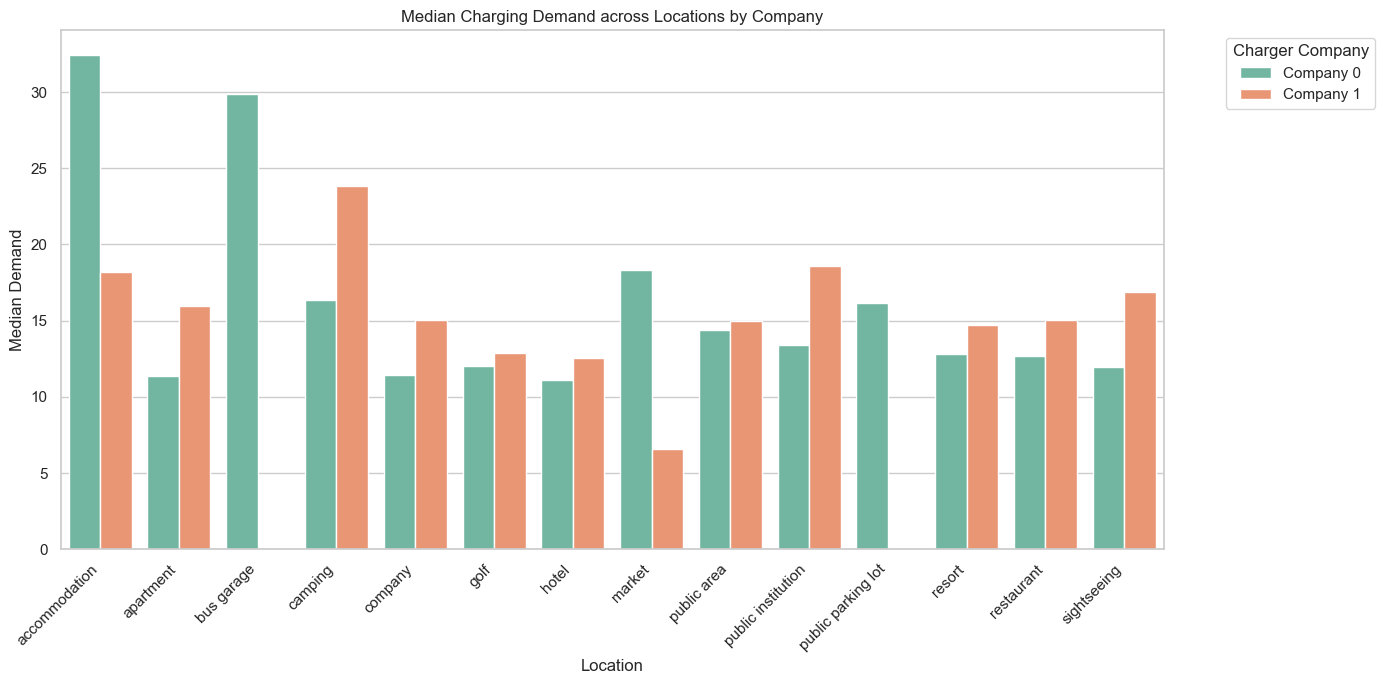

In [17]:
sns.set_theme(style="whitegrid")

# 1. Group by location and chargercompany_label
location_company_demand = df.groupby(["location", "chargercompany_label"], as_index=False).agg(
    median_demand=("demand", "median"),
    median_duration=("duration", "median"),
    sessions=("demand", "size")
)

plt.figure(figsize=(14, 7))

# 2. Corrected hue name ('chargercompany_label') and direct plotting of average_demand
sns.barplot(
    data=location_company_demand, 
    x='location', 
    y='median_demand', 
    hue='chargercompany_label',
    palette='Set2'
)

plt.title('Median Charging Demand across Locations by Company')
plt.xlabel('Location')
plt.ylabel('Median Demand')
plt.xticks(rotation=45, ha='right')
plt.legend(title="Charger Company",bbox_to_anchor=(1.05, 1),loc="upper left")
plt.tight_layout()
plt.show()

## 5.2 Duration × Demand × Company × Charger Type

These scatterplots combine four dimensions:

- X-axis → duration
- Y-axis → demand
- colour → charger company
- separate panels → charger type

### Interpretation
The duration-demand relationship changes across charger types. Type 0 sessions cover a much wider duration range, while Type 1 sessions are concentrated at shorter durations. This interaction supports treating charger type and charger company as useful categorical model features.

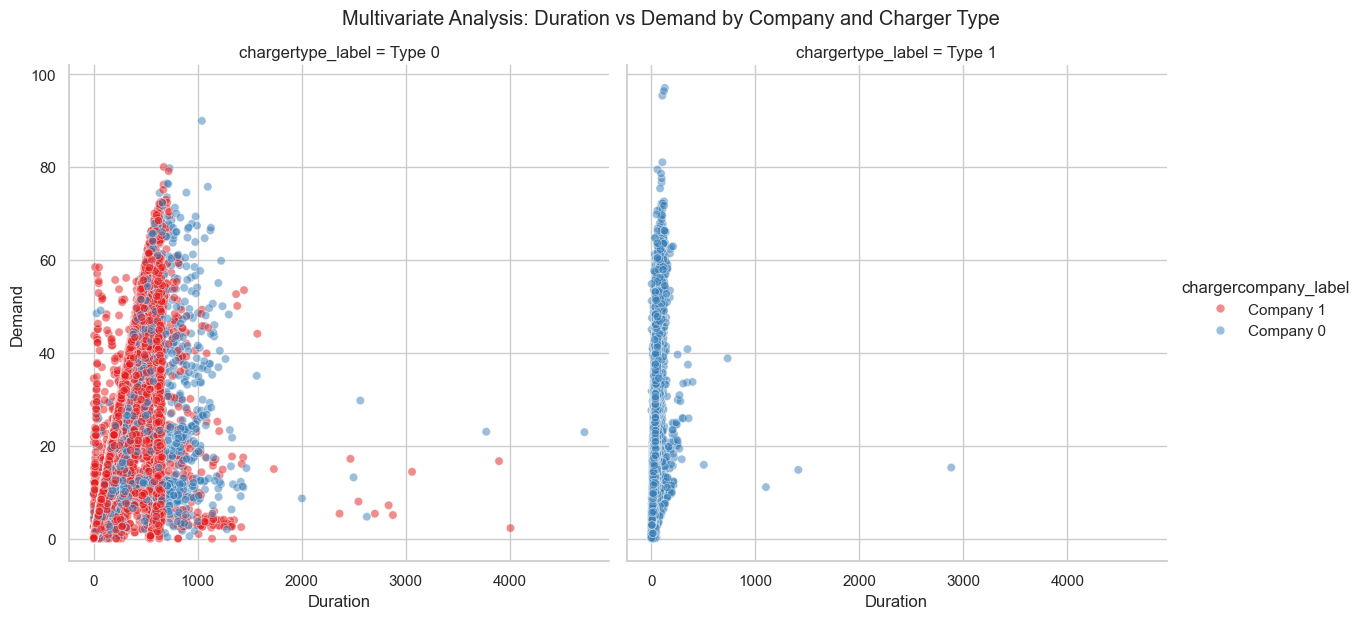

In [18]:
sns.set_theme(style="whitegrid")

# Using relplot to map 4 variables simultaneously
g = sns.relplot(
    data=df,
    x='duration',             # Variable 1: X-axis 
    y='demand',              # Variable 2: Y-axis
    hue='chargercompany_label',  # Variable 3: Different colors for each Company
    col='chargertype_label',     # Variable 4: Separate subplots for each Charger Type
    kind='scatter',
    alpha=0.5,                   # Transparency to handle overlapping points
    palette='Set1',
    height=6,
    aspect=1
)

# Adjusting titles and labels
g.set_axis_labels('Duration', 'Demand')
g.fig.suptitle('Multivariate Analysis: Duration vs Demand by Company and Charger Type', y=1.03)
plt.show()

# 6. Daily demand trend and 7-day rolling average

The data is grouped by date to create a daily summary containing:
- session count
- average demand
- average duration

The 7-day rolling value for each date is calculated using that date and the preceding six available dates. It smooths short-term daily fluctuations and makes the underlying demand pattern easier to observe.

```text
7-day rolling average
= average of the current day and nearby recent days within a 7-day window
```
### interpret
- light/raw line → actual daily average demand
- smoother line → 7-day average trend

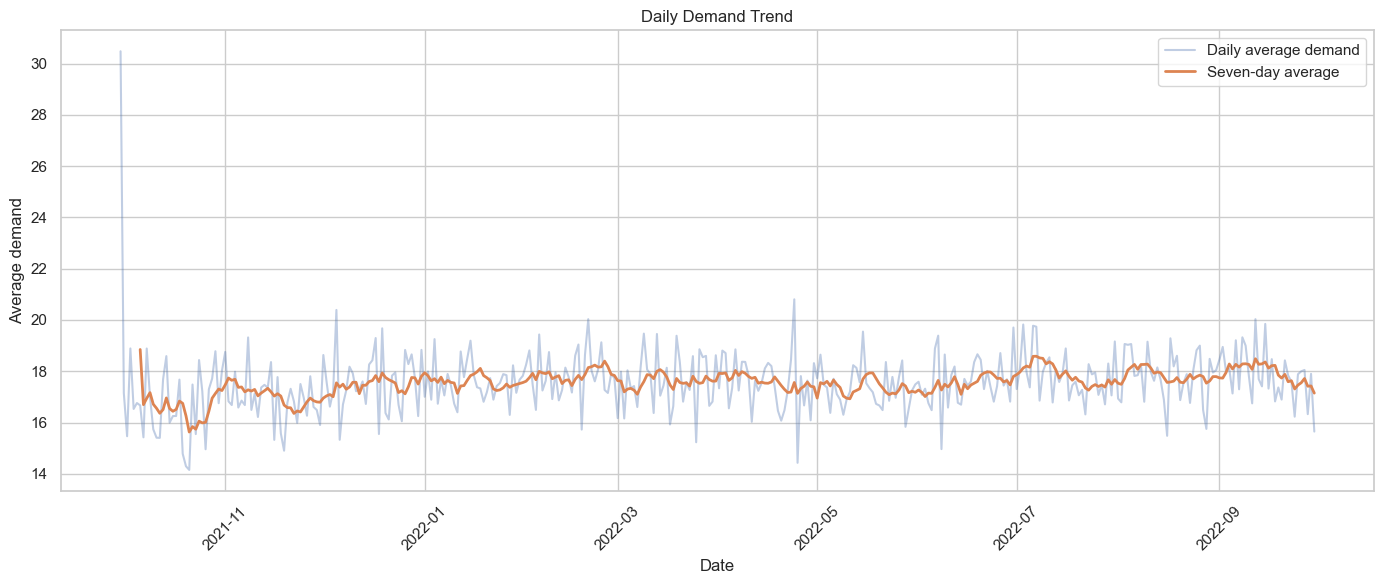

In [19]:
daily_summary = (
    df.groupby("start_date", as_index=False)
    .agg(
        sessions=("userid", "size"),
        average_demand=("demand", "mean"),
        average_duration=("duration", "mean")
    )
    .sort_values("start_date")
)

daily_summary["seven_day_average_demand"] = (
    daily_summary["average_demand"]
    .rolling(window=7)
    .mean()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_summary,
    x="start_date",
    y="average_demand",
    label="Daily average demand",
    alpha=0.35,
)

sns.lineplot(
    data=daily_summary,
    x="start_date",
    y="seven_day_average_demand",
    label="Seven-day average",
    linewidth=2,
)

plt.title("Daily Demand Trend")
plt.xlabel("Date")
plt.ylabel("Average demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.close()

# 7. Correlation analysis across numerical features

The notebook creates a numeric correlation matrix using:

- `duration`
- `demand`
- `start_hour`

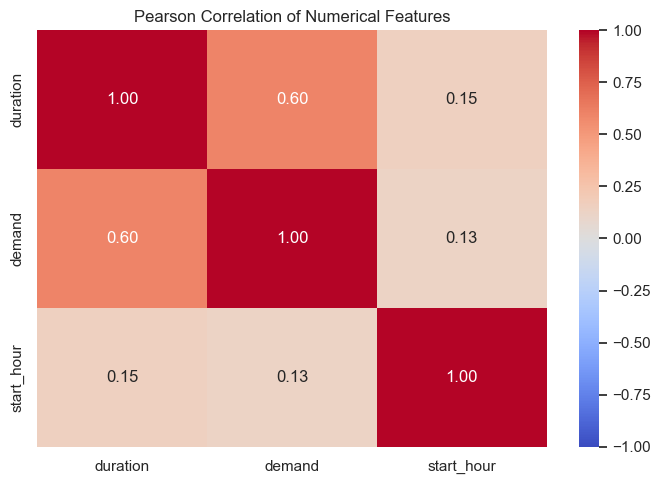

In [20]:
# Correlation of the main numerical measurements

correlation_columns = [
    "duration",
    "demand",
    "start_hour"
]

pearson_correlation = df[correlation_columns].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    pearson_correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Pearson Correlation of Numerical Features")
plt.tight_layout()
plt.show()

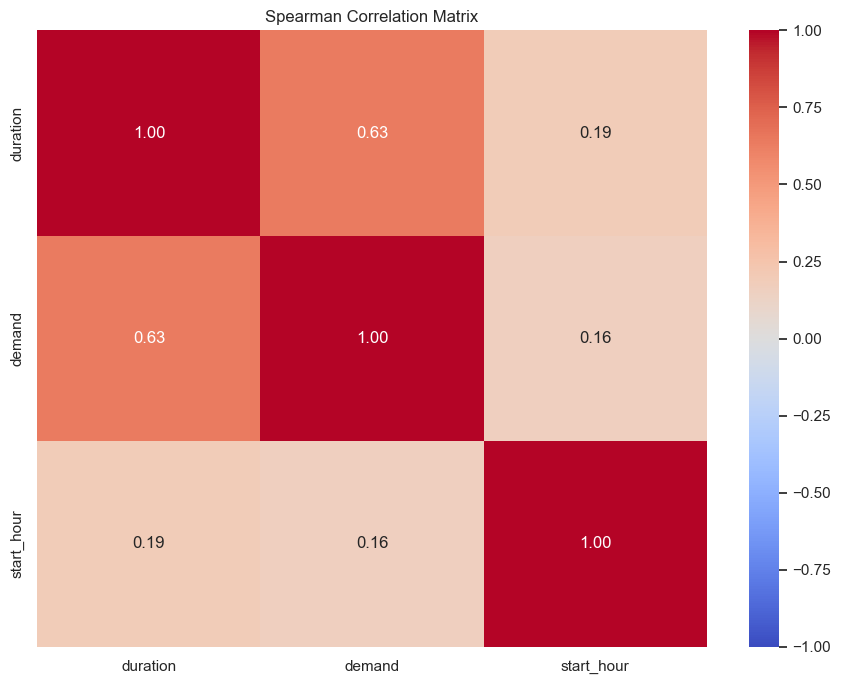

In [21]:
spearman_correlation = df[correlation_columns].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(
    spearman_correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
)
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()
plt.close()

# 8. Confirm retained outliers and complete EDA

The exploratory analysis is now complete. The following section creates model-ready calendar, time-of-day, and historical-usage features. These engineered columns will be used in the Regression and Classification notebooks.

The data is sorted chronologically before creating historical counts. Therefore, each row only counts sessions that occurred before the current session, helping prevent future-data leakage.

```text
Duration outliers retained: 4120
Demand outliers retained:   3528
```

In [22]:
# ============================================================
# 17. Show retained outlier counts,
# if the cleaning script created the flags.
# ============================================================

if "duration_outlier" in df.columns:
    print(
        "\nDuration outliers retained:",
        df["duration_outlier"].sum()
    )

if "demand_outlier" in df.columns:
    print(
        "Demand outliers retained:",
        df["demand_outlier"].sum()
    )

print("\nEDA complete.")



Duration outliers retained: 4120
Demand outliers retained: 3528

EDA complete.


In [23]:
df.columns

Index(['userid', 'chargerid', 'chargercompany', 'location', 'chargertype',
       'startday', 'starttime', 'endday', 'endtime', 'startdatetime',
       'enddatetime', 'duration', 'demand', 'start_full', 'end_full',
       'duration_original', 'duration_calculated', 'duration_mismatch',
       'duration_outlier', 'demand_outlier', 'start_hour', 'start_date',
       'day_of_week_number', 'day_of_week', 'chargercompany_label',
       'chargertype_label', 'log_duration', 'log_demand'],
      dtype='object')

# Feature Engineering

In [24]:
import numpy as np

# Purpose: Display the current record count and columns before engineering new features.
print("Rows before feature engineering:", len(df))
print("Columns before feature engineering:", df.columns.tolist())


Rows before feature engineering: 72241
Columns before feature engineering: ['userid', 'chargerid', 'chargercompany', 'location', 'chargertype', 'startday', 'starttime', 'endday', 'endtime', 'startdatetime', 'enddatetime', 'duration', 'demand', 'start_full', 'end_full', 'duration_original', 'duration_calculated', 'duration_mismatch', 'duration_outlier', 'demand_outlier', 'start_hour', 'start_date', 'day_of_week_number', 'day_of_week', 'chargercompany_label', 'chargertype_label', 'log_duration', 'log_demand']


In [25]:
# Purpose: Validate required columns and sort by start timestamp before counting past sessions.
required_columns = [
    "userid", "chargerid", "chargercompany", "location", "chargertype",
    "start_full", "start_hour", "day_of_week_number", "day_of_week",
    "duration", "demand",
]

for column in required_columns:
    if column not in df.columns:
        raise ValueError("Missing required column: " + column)

invalid_start_dates = df["start_full"].isnull().sum()
print("Invalid start dates:", invalid_start_dates)

# Records with missing start timestamps cannot be ordered or assigned calendar features.
df = df.dropna(subset=["start_full"]).copy()

df = df.sort_values("start_full").reset_index(drop=True)


Invalid start dates: 0


In [26]:
# Calander and time datatypes

# 4. Extract date and time parts
# These columns make it possible for a model to learn usage patterns.
df["start_year"] = df["start_full"].dt.year
df["start_month"] = df["start_full"].dt.month
df["start_day"] = df["start_full"].dt.day
df["start_minute"] = df["start_full"].dt.minute
df["week_of_year"] = df["start_full"].dt.isocalendar().week.astype(int)
df["day_name"] = df["day_of_week"]

month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December",
}

df["month_name"] = df["start_month"].map(month_names)

# 6. Create weekday/weekend features
df["is_weekend"] = df["day_of_week_number"].isin([5, 6]).astype(int)

df["is_weekday"] = df["day_of_week_number"].isin(
    [0, 1, 2, 3, 4]
).astype(int)

df["day_type"] = df["is_weekend"].map(
    {0: "Weekday", 1: "Weekend"}
)

# 7. Create time-of-day categories
# These groups are easy to explain in an EDA report.
def get_time_of_day(hour):
    if hour < 6:
        return "Night"
    elif hour < 12:
        return "Morning"
    elif hour < 17:
        return "Afternoon"
    elif hour < 21:
        return "Evening"
    else:
        return "Night"

df["time_of_day"] = df["start_hour"].apply(get_time_of_day)

In [27]:
# Purpose: Confirm `day_name` duplicates `day_of_week` before removing the redundant column.
assert (df["day_name"] == df["day_of_week"]).all(), "Weekday labels do not match"
df[["day_name", "day_of_week"]].head()

,day_name,day_of_week
0,Thursday,Thursday
1,Thursday,Thursday
2,Thursday,Thursday
3,Thursday,Thursday
4,Thursday,Thursday


In [28]:
# Remove the redundant `day_of_week` label because `day_name` stores the same values.
df = df.drop(columns=["day_of_week"])

In [29]:
# Historical features
# 1. Cumulative Session Counts (Simple & No NaNs)
df["user_previous_sessions"] = df.groupby("userid").cumcount()
df["charger_previous_sessions"] = df.groupby("chargerid").cumcount()
df["location_previous_sessions"] = df.groupby("location").cumcount()

In [30]:
columns_to_remove = ['userid', 'chargerid','startday', 'starttime', 'endday', 'endtime', 'startdatetime',
       'enddatetime', 'end_full','duration_original', 'duration_calculated', 'duration_mismatch',
       'duration_outlier', 'demand_outlier',  'start_date',
       'day_of_week_number', 'chargercompany_label', 'chargertype_label',
       'log_duration', 'log_demand', 'start_year', 'start_month', 'is_weekend','is_weekday' ]
	   
# 4. Drop the listed columns safely
df = df.drop(columns=columns_to_remove, errors='ignore')

In [31]:
df.columns

Index(['chargercompany', 'location', 'chargertype', 'duration', 'demand',
       'start_full', 'start_hour', 'start_day', 'start_minute', 'week_of_year',
       'day_name', 'month_name', 'day_type', 'time_of_day',
       'user_previous_sessions', 'charger_previous_sessions',
       'location_previous_sessions'],
      dtype='object')

In [32]:
features = [
    "duration",
    "start_day",
    "start_hour",
    "start_minute",
    "week_of_year",
    "user_previous_sessions",
    "charger_previous_sessions",
    "location_previous_sessions",
    "chargercompany",
    "location",
    "chargertype",
    "month_name",
    "day_name",
    "day_type",
    "time_of_day"
]

# Check whether every required modeling feature exists in the DataFrame
missing_cols = [col for col in features if col not in df.columns]

# Report the result clearly
if not missing_cols:
    print("All features are present in the DataFrame!")
else:
    print(f"Missing columns ({len(missing_cols)}):", missing_cols)

All features are present in the DataFrame!


In [33]:
# 1. Check for duplicate column names
print("Duplicate column names:", df.columns.duplicated().sum())


# 2. Check whether all model features are available
required_columns = features + ["demand", "start_full"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

extra_columns = [
    col for col in df.columns
    if col not in required_columns
]

print("Missing columns:", missing_columns)
print("Extra columns:", extra_columns)


# 3. Check missing values in start_full
print("Missing timestamps:", df["start_full"].isna().sum())


# 4. Check chronological sorting
print("Data sorted by start time:",
      df["start_full"].is_monotonic_increasing)


# 5. Check negative historical session counts
print("Negative user sessions:",
      (df["user_previous_sessions"] < 0).sum())

print("Negative charger sessions:",
      (df["charger_previous_sessions"] < 0).sum())

print("Negative location sessions:",
      (df["location_previous_sessions"] < 0).sum())

Duplicate column names: 0
Missing columns: []
Extra columns: []
Missing timestamps: 0
Data sorted by start time: True
Negative user sessions: 0
Negative charger sessions: 0
Negative location sessions: 0


In [34]:
if not df["start_full"].is_monotonic_increasing:
    raise ValueError("Data must be sorted before saving")

# Save the complete feature-engineered dataset
df.to_csv("data/ev_charging_featured.csv", index=False)

print("\nFeature-engineered file saved as ev_charging_featured.csv!",)
print("Rows after feature engineering:", len(df))


Feature-engineered file saved as ev_charging_featured.csv!
Rows after feature engineering: 72241
